Camelyon17 — SmallCNN with Data Augmentation
ELE680 — Group 7: Tumor Detection across Hospitals

Objective
Train a SmallCNN using data augmentation and compare its performance against the SmallCNN baseline without augmentation.

We use the official Camelyon17-WILDS hospital splits to investigate how well the model generalizes to unseen hospitals.

In [1]:
import os
import torch

print("Visible GPU setting:", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("Visible GPU count:", torch.cuda.device_count())
print("GPU name:", torch.cuda.get_device_name(0))

Visible GPU setting: 3
Visible GPU count: 1
GPU name: Tesla P100-PCIE-12GB


In [2]:
import torch
import torchvision
import numpy as np
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.5.1+cu118
CUDA available: True


In [3]:
from wilds import get_dataset

DATA_ROOT = "/mnt/beegfs/scratch/camelyon17/data"

dataset = get_dataset(
    dataset="camelyon17",
    root_dir=DATA_ROOT,
    download=False
)

print("Dataset loaded successfully!")
print("Total image patches:", len(dataset))

Dataset loaded successfully!
Total image patches: 455954


In [4]:
train_data = dataset.get_subset("train")
id_val_data = dataset.get_subset("id_val")
ood_val_data = dataset.get_subset("val")
test_data = dataset.get_subset("test")

print("Training images:", len(train_data))
print("ID validation images:", len(id_val_data))
print("OOD validation images:", len(ood_val_data))
print("Test images:", len(test_data))

Training images: 302436
ID validation images: 33560
OOD validation images: 34904
Test images: 85054


In [5]:
from torchvision import transforms

IMAGE_SIZE = 96

# Augmentation for training images only
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # 1. Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # 2. Random vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # 3. Random rotation by 0, 90, 180, or 270 degrees
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270)),
    ]),

    # 4. Mild color jitter
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Validation and test images: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

print("All four augmentation types are ready!")


All four augmentation types are ready!


In [6]:
# Training data
train_data = dataset.get_subset(
    "train",
    transform=train_transform
)

# ID validation: no augmentation
id_val_data = dataset.get_subset(
    "id_val",
    transform=eval_transform
)

# OOD validation: no augmentation
ood_val_data = dataset.get_subset(
    "val",
    transform=eval_transform
)

# Test data: no augmentation
test_data = dataset.get_subset(
    "test",
    transform=eval_transform
)

print("Transforms applied successfully!")
print("Training images:", len(train_data))
print("ID validation images:", len(id_val_data))
print("OOD validation images:", len(ood_val_data))
print("Test images:", len(test_data))

Transforms applied successfully!
Training images: 302436
ID validation images: 33560
OOD validation images: 34904
Test images: 85054


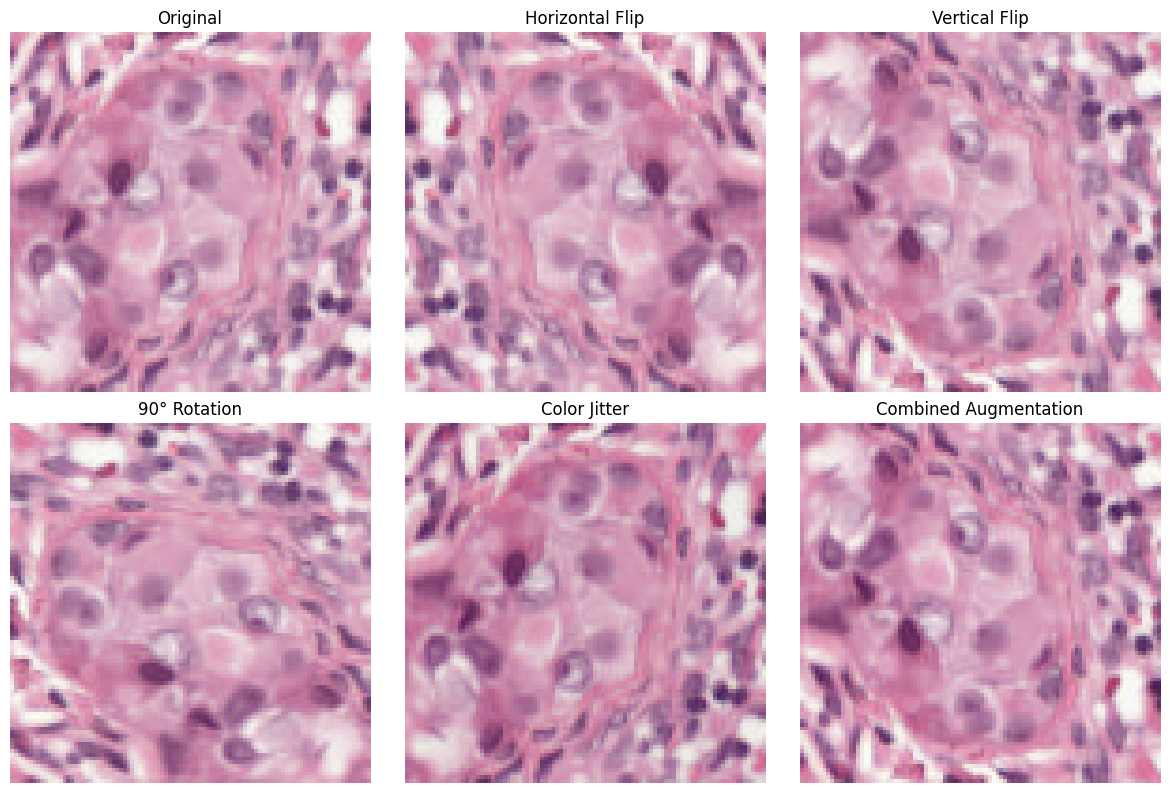

In [7]:
import matplotlib.pyplot as plt
from torchvision import transforms

# Use the same original training image for every example
original_image, label, metadata = dataset.get_subset("train")[0]

resize = transforms.Resize((96, 96))

# Apply each augmentation separately
horizontal_flip = transforms.RandomHorizontalFlip(p=1.0)
vertical_flip = transforms.RandomVerticalFlip(p=1.0)
rotation_90 = transforms.RandomRotation((90, 90))

color_jitter = transforms.ColorJitter(
    brightness=0.1,
    contrast=0.1,
    saturation=0.1
)

images = [
    resize(original_image),
    horizontal_flip(resize(original_image)),
    vertical_flip(resize(original_image)),
    rotation_90(resize(original_image)),
    color_jitter(resize(original_image))
]

# Combined augmentation is normalized, so undo normalization for display
combined_tensor = train_transform(original_image)
combined_image = transforms.ToPILImage()(
    (combined_tensor * 0.5 + 0.5).clamp(0, 1)
)

images.append(combined_image)

titles = [
    "Original",
    "Horizontal Flip",
    "Vertical Flip",
    "90° Rotation",
    "Color Jitter",
    "Combined Augmentation"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 192, kernel_size=3, padding=1),
            nn.BatchNorm2d(192),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(192, 2)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


model = SmallCNN()

print("CNN model created successfully!")
print(model)

CNN model created successfully!
SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=

In [9]:
# Get one augmented training image
image, label, metadata = train_data[0]

# Add a batch dimension: [3, 96, 96] -> [1, 3, 96, 96]
image_batch = image.unsqueeze(0)

# Test the model without training it
model.eval()

with torch.no_grad():
    output = model(image_batch)

print("Input shape:", image_batch.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([1, 3, 96, 96])
Output shape: torch.Size([1, 2])


In [18]:
# Training settings 

BATCH_SIZE = 8
EPOCHS = 16
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4

# Use GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Data loader workers:", NUM_WORKERS)
print("Device:", device)

Batch size: 8
Epochs: 16
Learning rate: 0.001
Weight decay: 0.0001
Data loader workers: 4
Device: cuda


In [19]:
import torch.optim as optim

# Move SmallCNN to the GPU
model = model.to(device)

# Loss function for normal vs. tumor classification
criterion = nn.CrossEntropyLoss()

# AdamW optimizer with weight decay matching Benjamin's baseline
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Model device:", next(model.parameters()).device)
print("Loss function:", criterion)
print("Optimizer: AdamW")
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])

Model device: cuda:0
Loss function: CrossEntropyLoss()
Optimizer: AdamW
Weight decay: 0.0001


In [20]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Training images:", len(train_data))

Training batches: 37805
Training images: 302436


In [21]:
# Validation DataLoaders

id_val_loader = DataLoader(
    id_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

ood_val_loader = DataLoader(
    ood_val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("ID validation images:", len(id_val_data))
print("OOD validation images:", len(ood_val_data))
print("ID validation batches:", len(id_val_loader))
print("OOD validation batches:", len(ood_val_loader))

ID validation images: 33560
OOD validation images: 34904
ID validation batches: 4195
OOD validation batches: 4363


In [22]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

def calculate_metrics(y_true, y_pred, y_prob):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob)
    }
    return metrics


In [23]:
def evaluate_model(model, data_loader, device):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels, metadata in data_loader:
            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    metrics = calculate_metrics(
        all_labels,
        all_predictions,
        all_probabilities
    )

    return metrics


print("Model evaluation function created successfully!")

Model evaluation function created successfully!


In [24]:
from pathlib import Path

# project's existing checkpoints folder
CHECKPOINT_DIR = Path(
    "/mnt/beegfs/home/u283598/final_project/checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# New filenames for the corrected weight decay experiment
latest_checkpoint_path = CHECKPOINT_DIR / "smallcnn_aug_wd1e4_latest.pt"
best_checkpoint_path = CHECKPOINT_DIR / "smallcnn_aug_wd1e4_best.pt"

if latest_checkpoint_path.exists() or best_checkpoint_path.exists():
    raise FileExistsError(
        "A corrected SmallCNN checkpoint already exists. "
        "Stop here to avoid overwriting it."
    )

print("Checkpoint folder:", CHECKPOINT_DIR)
print("Latest checkpoint:", latest_checkpoint_path.name)
print("Best checkpoint:", best_checkpoint_path.name)
print("Original checkpoints will not be overwritten.")

Checkpoint folder: /mnt/beegfs/home/u283598/final_project/checkpoints
Latest checkpoint: smallcnn_aug_wd1e4_latest.pt
Best checkpoint: smallcnn_aug_wd1e4_best.pt
Original checkpoints will not be overwritten.


In [25]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels, metadata in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and update model weights
        loss.backward()
        optimizer.step()

        # Track training loss and accuracy
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        correct_predictions += (predictions == labels).sum().item()
        total_images += labels.size(0)

    epoch_loss = running_loss / total_images
    epoch_accuracy = correct_predictions / total_images

    return epoch_loss, epoch_accuracy


print("Training function created successfully!")

Training function created successfully!


In [ ]:
# training starts for 16-epoch
assert optimizer.param_groups[0]["weight_decay"] == 1e-4

# Protect existing checkpoints
if latest_checkpoint_path.exists() or best_checkpoint_path.exists():
    raise FileExistsError(
        "Corrected checkpoints already exist. "
        "Do not overwrite them."
    )

history = {
    "train_loss": [],
    "train_accuracy": [],
    "id_val_accuracy": [],
    "id_val_balanced_accuracy": [],
    "id_val_auc": [],
    "ood_val_accuracy": [],
    "ood_val_balanced_accuracy": [],
    "ood_val_auc": []
}

best_ood_balanced_accuracy = -1.0
best_epoch = 0

for epoch in range(EPOCHS):

    # Train for one epoch
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Evaluate on both validation sets
    id_metrics = evaluate_model(model, id_val_loader, device)
    ood_metrics = evaluate_model(model, ood_val_loader, device)

    # Record results
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["id_val_accuracy"].append(id_metrics["accuracy"])
    history["id_val_balanced_accuracy"].append(
        id_metrics["balanced_accuracy"]
    )
    history["id_val_auc"].append(id_metrics["auc"])

    history["ood_val_accuracy"].append(ood_metrics["accuracy"])
    history["ood_val_balanced_accuracy"].append(
        ood_metrics["balanced_accuracy"]
    )
    history["ood_val_auc"].append(ood_metrics["auc"])

    # Save the latest checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "history": history,
        "weight_decay": WEIGHT_DECAY
    }

    torch.save(checkpoint, latest_checkpoint_path)

    # Save the best model based on OOD balanced accuracy
    if ood_metrics["balanced_accuracy"] > best_ood_balanced_accuracy:
        best_ood_balanced_accuracy = ood_metrics["balanced_accuracy"]
        best_epoch = epoch + 1

        torch.save(checkpoint, best_checkpoint_path)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"ID Val Acc: {id_metrics['accuracy']:.4f} | "
        f"OOD Val Acc: {ood_metrics['accuracy']:.4f} | "
        f"OOD Balanced Acc: {ood_metrics['balanced_accuracy']:.4f} | "
        f"OOD AUC: {ood_metrics['auc']:.4f}",
        flush=True
    )

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best OOD balanced accuracy:", best_ood_balanced_accuracy)
print("Best checkpoint:", best_checkpoint_path)

In [3]:
# Load completed training history without retraining
import torch

checkpoint_path = (
    "/mnt/beegfs/home/u283598/final_project/"
    "checkpoints/smallcnn_aug_wd1e4_best.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

history = checkpoint["history"]

print("Checkpoint epoch:", checkpoint["epoch"])
print("Weight decay:", checkpoint["weight_decay"])
print("\nSaved history fields:")

for key, values in history.items():
    print(f"{key}: {len(values)} epochs")

Checkpoint epoch: 16
Weight decay: 0.0001

Saved history fields:
train_loss: 16 epochs
train_accuracy: 16 epochs
id_val_accuracy: 16 epochs
id_val_balanced_accuracy: 16 epochs
id_val_auc: 16 epochs
ood_val_accuracy: 16 epochs
ood_val_balanced_accuracy: 16 epochs
ood_val_auc: 16 epochs


In [4]:
# Load official test results from the completed evaluation

import json
from pathlib import Path

results_path = Path(
    "/mnt/beegfs/home/u283598/final_project/"
    "smallcnn_aug_wd1e4_test_results.json"
)

with open(results_path, "r") as f:
    test_results = json.load(f)

metrics = test_results["test_metrics"]

print("-" * 55)
print(f"Checkpoint epoch: {test_results['checkpoint_epoch']}")
print(f"Test images: {test_results['test_images']:,}")
print(f"Test accuracy: {metrics['accuracy'] * 100:.2f}%")
print(f"Balanced accuracy: {metrics['balanced_accuracy'] * 100:.2f}%")
print(f"ROC-AUC: {metrics['auc']:.4f}")

-------------------------------------------------------
Checkpoint epoch: 16
Test images: 85,054
Test accuracy: 91.22%
Balanced accuracy: 91.22%
ROC-AUC: 0.9552


In [5]:
# Training and validation results for all 16 epochs
import pandas as pd

epoch_results = pd.DataFrame({
    "Epoch": range(1, 17),
    "Train Loss": history["train_loss"],
    "Train Accuracy (%)": [
        x * 100 for x in history["train_accuracy"]
    ],
    "ID Val Accuracy (%)": [
        x * 100 for x in history["id_val_accuracy"]
    ],
    "OOD Val Accuracy (%)": [
        x * 100 for x in history["ood_val_accuracy"]
    ],
    "OOD Val Balanced Accuracy (%)": [
        x * 100 for x in history["ood_val_balanced_accuracy"]
    ],
    "OOD Val ROC-AUC": history["ood_val_auc"],
})

print("SMALLCNN WITH AUGMENTATION — ALL 16 TRAINING EPOCHS")
print("Weight decay: 0.0001")

display(epoch_results.round(4))

SMALLCNN WITH AUGMENTATION — ALL 16 TRAINING EPOCHS
Weight decay: 0.0001


,Epoch,Train Loss,Train Accuracy (%),ID Val Accuracy (%),OOD Val Accuracy (%),OOD Val Balanced Accuracy (%),OOD Val ROC-AUC
0,1,0.1686,93.7154,96.7014,86.0217,86.0217,0.9614
1,2,0.0934,96.7117,97.9321,85.4716,85.4716,0.8998
2,3,0.0755,97.3832,97.7086,80.2745,80.2745,0.8466
3,4,0.0674,97.7003,98.3611,87.6633,87.6633,0.9311
4,5,0.0620,97.8557,98.2181,88.4168,88.4168,0.9636
5,6,0.0580,98.0217,98.5131,86.6720,86.6720,0.9223
6,7,0.0552,98.1209,98.2509,87.1390,87.1390,0.9142
7,8,0.0519,98.2495,98.5906,88.7778,88.7778,0.9197
8,9,0.0504,98.2823,98.6889,89.5886,89.5886,0.9558
9,10,0.0484,98.3583,98.5727,79.0139,79.0139,0.8743


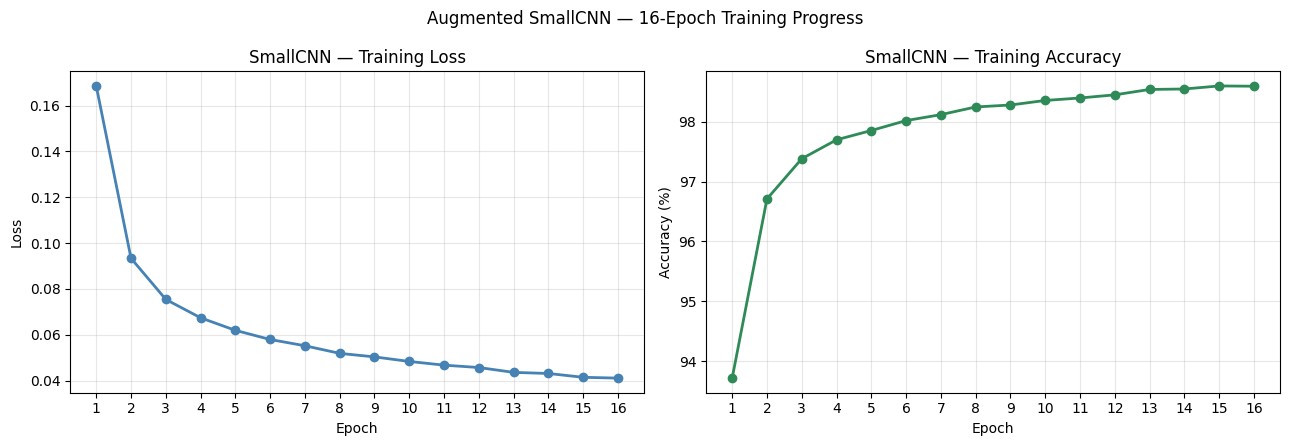

In [6]:
# Training curves across all 16 epochs
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Training loss
axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    color="steelblue",
    linewidth=2
)
axes[0].set_title("SmallCNN — Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(list(epochs))
axes[0].grid(alpha=0.3)

# Training accuracy
axes[1].plot(
    epochs,
    [value * 100 for value in history["train_accuracy"]],
    marker="o",
    color="seagreen",
    linewidth=2
)
axes[1].set_title("SmallCNN — Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_xticks(list(epochs))
axes[1].grid(alpha=0.3)

plt.suptitle("Augmented SmallCNN — 16-Epoch Training Progress")
plt.tight_layout()
plt.show()

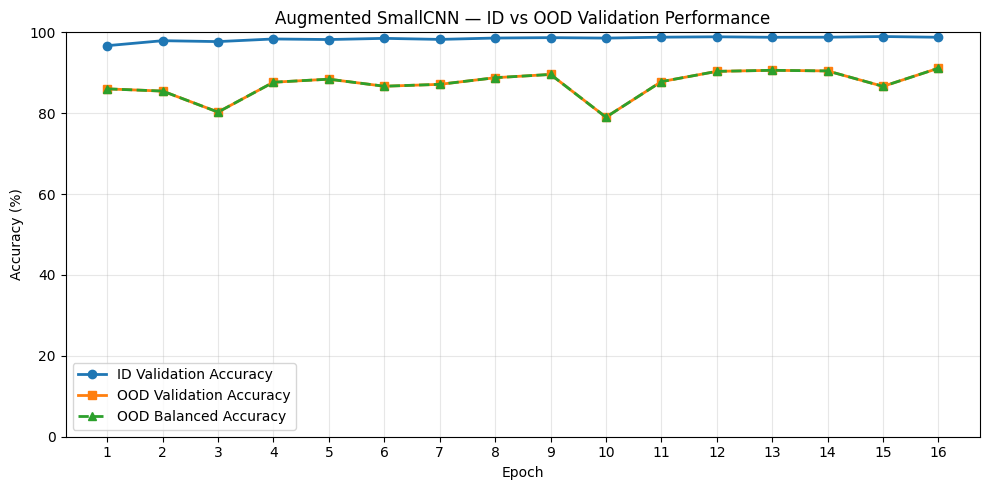

In [7]:
# ID and OOD validation performance across all 16 epochs

epochs = range(1, len(history["id_val_accuracy"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    [x * 100 for x in history["id_val_accuracy"]],
    marker="o",
    linewidth=2,
    label="ID Validation Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in history["ood_val_accuracy"]],
    marker="s",
    linewidth=2,
    label="OOD Validation Accuracy"
)

plt.plot(
    epochs,
    [x * 100 for x in history["ood_val_balanced_accuracy"]],
    marker="^",
    linestyle="--",
    linewidth=2,
    label="OOD Balanced Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Augmented SmallCNN — ID vs OOD Validation Performance")
plt.xticks(list(epochs))
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

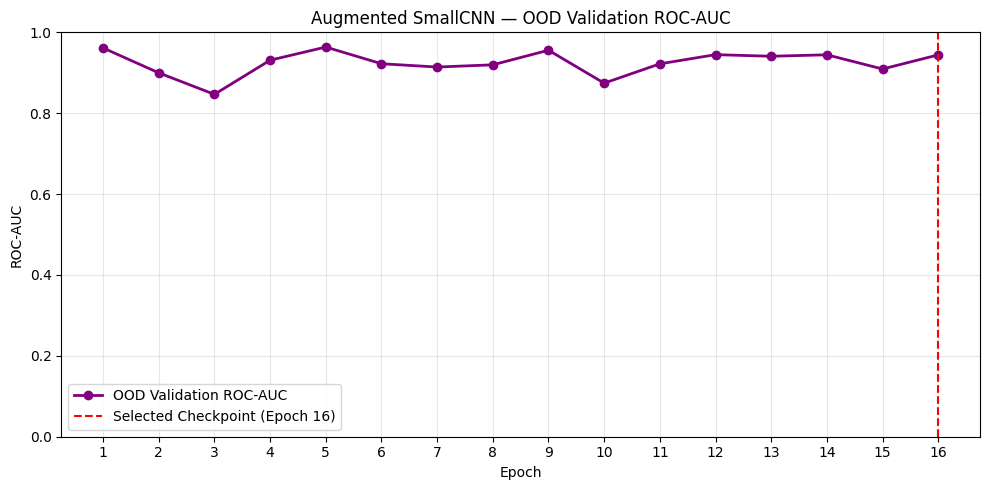

In [8]:
# OOD validation ROC-AUC across all 16 epochs

epochs = list(range(1, len(history["ood_val_auc"]) + 1))

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["ood_val_auc"],
    marker="o",
    linewidth=2,
    color="purple",
    label="OOD Validation ROC-AUC"
)

# Best checkpoint selected using OOD balanced accuracy
best_epoch = checkpoint["epoch"]

plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Selected Checkpoint (Epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Augmented SmallCNN — OOD Validation ROC-AUC")
plt.xticks(epochs)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
# selected best checkpoint

best_epoch = checkpoint["epoch"]
best_index = best_epoch - 1

print("BEST CHECKPOINT SUMMARY")
print("-" * 45)
print(f"Selected epoch: {best_epoch}")
print(f"Weight decay: {checkpoint['weight_decay']}")
print(f"Training accuracy: {history['train_accuracy'][best_index] * 100:.2f}%")
print(f"ID validation accuracy: {history['id_val_accuracy'][best_index] * 100:.2f}%")
print(f"OOD validation accuracy: {history['ood_val_accuracy'][best_index] * 100:.2f}%")
print(f"OOD validation balanced accuracy: {history['ood_val_balanced_accuracy'][best_index] * 100:.2f}%")
print(f"OOD validation ROC-AUC: {history['ood_val_auc'][best_index]:.4f}")
print()
print("Selection criterion: Highest OOD validation balanced accuracy")

BEST CHECKPOINT SUMMARY
---------------------------------------------
Selected epoch: 16
Weight decay: 0.0001
Training accuracy: 98.60%
ID validation accuracy: 98.78%
OOD validation accuracy: 91.13%
OOD validation balanced accuracy: 91.13%
OOD validation ROC-AUC: 0.9443

Selection criterion: Highest OOD validation balanced accuracy


## Official Test Evaluation — Augmented SmallCNN (Weight Decay = 1e-4)

The model was trained for 16 epochs using AdamW with weight decay
of 0.0001. The best checkpoint was selected using out-of-distribution
(OOD) validation balanced accuracy.

The selected checkpoint was evaluated on the official Camelyon17-WILDS
test split containing 85,054 images from a held-out hospital.

The test evaluation uses deterministic preprocessing (96 × 96 resize,
tensor conversion, and normalization), without random augmentation.


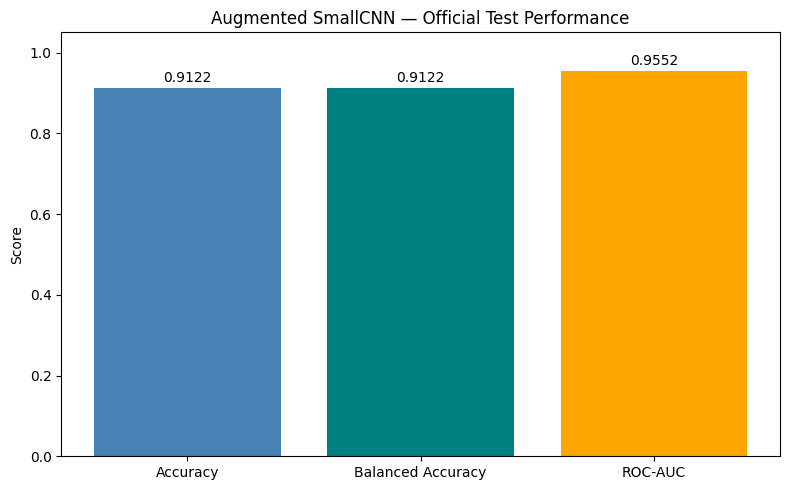

In [2]:
# Visualize official test performance
import matplotlib.pyplot as plt

metric_names = ["Accuracy", "Balanced Accuracy", "ROC-AUC"]
metric_values = [
    metrics["accuracy"],
    metrics["balanced_accuracy"],
    metrics["auc"]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values, color=["steelblue", "teal", "orange"])

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Augmented SmallCNN — Official Test Performance")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### Interpretation of Official Test Results

The corrected augmented SmallCNN achieved 91.22% accuracy,
91.22% balanced accuracy, and a ROC-AUC of 0.9552 on the
official Camelyon17-WILDS test set of 85,054 images.

The high ROC-AUC indicates that the model can distinguish
between tumor and non-tumor patches effectively across
different classification thresholds.

The OOD validation balanced accuracy was 91.13%, compared
with 91.22% on the official test set. These similar results
suggest consistent performance across the evaluated
held-out hospital environments.

The best checkpoint was selected using OOD validation
balanced accuracy, not test performance.


## Conclusion and Limitations

The corrected augmented SmallCNN achieved **91.22% test accuracy** and **0.9552 ROC-AUC** on the official Camelyon17-WILDS test split. Compared with the SmallCNN baseline accuracy of **85.39%**, this represents an improvement of **5.83 percentage points**. The results suggest that data augmentation can improve generalization across hospitals, although performance on other medical datasets remains untested.